# Regressão Linear — Consumo de Energia × Tarifas (EPE + ANEEL) — **versão corrigida**

**Objetivo:** investigar a associação entre o consumo mensal **residencial** de energia (EPE) e a tarifa **residencial** média (ANEEL).

## O que foi corrigido em relação à versão original

| # | Bug | Correção |
|---|-----|----------|
| 1 | O consumo era somado **com a linha "Total Geral"** da tabela dinâmica, ficando **2× maior** | Passamos a usar a aba tabular `CONSUMO E NUMCONS SAM` (sem linha de total) e, por segurança, removemos qualquer linha "Total" |
| 2 | Os nomes dos arquivos (`...(1).xlsx`, `...(2).csv`) não batiam com os arquivos reais, e o código sempre caía na janela do Tkinter | Agora o código procura os arquivos **por padrão de nome** (com ou sem "(1)", "(2)") e só abre a janela como último recurso |
| 3 | A tarifa média misturava Rural, Residencial, Iluminação pública e "Não se aplica" de todas as distribuidoras | Comparamos **maçã com maçã**: consumo da classe **Residencial** × tarifa **B1 Residencial, modalidade Convencional** |

> ⚠️ Essas correções arrumam os **bugs**. Elas **não** transformam o modelo em um bom modelo preditivo. No fim do notebook tem um diagnóstico comparando com um *baseline* para você ver isso com números.

## 1. Bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from pathlib import Path

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 2. Localização dos arquivos — **correção do bug 2**

**Antes:** o código procurava o nome exato `Dados_abertos_Consumo_Mensal_energia(1).xlsx`. Como o seu arquivo se chama `Dados_abertos_Consumo_Mensal_energia.xlsx` (sem o "(1)"), ele nunca achava e abria a janela do Tkinter.

**Agora:** usamos `glob` com um **padrão** (`Dados_abertos_Consumo_Mensal_energia*.xlsx`). O `*` aceita qualquer coisa no lugar, então pega o arquivo com ou sem "(1)". O Tkinter só é importado **se** nada for encontrado, assim o código não quebra em ambientes sem interface gráfica.

In [2]:
def localizar_arquivo(padrao, titulo, extensao, pastas=None):
    """Procura um arquivo por padrão (glob) nas pastas indicadas.
    Se não achar, abre uma janela de seleção como último recurso."""
    pastas = pastas or [Path.cwd(), Path.cwd().parent, Path.cwd() / "dados"]
    for pasta in pastas:
        encontrados = sorted(Path(pasta).glob(padrao))
        if encontrados:
            print(f"Arquivo localizado: {encontrados[0].resolve()}")
            return encontrados[0]

    # Último recurso: janela de seleção (import só aqui dentro)
    try:
        from tkinter import Tk, filedialog
        raiz = Tk(); raiz.withdraw(); raiz.attributes("-topmost", True)
        caminho = filedialog.askopenfilename(
            title=titulo,
            filetypes=[(f"Arquivo {extensao}", f"*{extensao}"), ("Todos os arquivos", "*.*")]
        )
        raiz.destroy()
    except Exception:
        caminho = ""

    if not caminho:
        raise FileNotFoundError(f"Não encontrei '{padrao}'. Coloque o arquivo na pasta do notebook.")
    return Path(caminho)

ARQUIVO_EPE = localizar_arquivo(
    "Dados_abertos_Consumo_Mensal_energia*.xlsx",
    "Selecione a planilha de consumo mensal da EPE", ".xlsx"
)
ARQUIVO_ANEEL = localizar_arquivo(
    "tarifas-homologadas-distribuidoras-energia-eletrica*.csv",
    "Selecione o CSV de tarifas homologadas da ANEEL", ".csv"
)

# Período de análise (mesmo da versão original)
DATA_INICIO = "2023-01"
DATA_FIM    = "2026-09"

## 3. Leitura do consumo EPE — **correção do bug 1**

**Antes:** o código lia a aba `ANALISE CONS NUMCONS SAM`, que é uma **tabela dinâmica**. Ela tem as 5 regiões **e** uma linha final chamada **"Total Geral"**. Como o código somava todas as linhas, o resultado era:

`Centro-Oeste + Nordeste + Norte + Sudeste + Sul + Total Geral` = **2× o consumo real**

**Agora:** lemos a aba **tabular** `CONSUMO E NUMCONS SAM`, que tem uma linha por *mês × região × classe × tipo de consumidor*. Ela não tem linha de total, e ainda traz a coluna **`Classe`**, que precisamos para corrigir o bug 3. Mesmo assim deixamos um filtro de segurança contra linhas "Total".

In [3]:
epe = pd.read_excel(ARQUIVO_EPE, sheet_name="CONSUMO E NUMCONS SAM")

# Filtro de segurança: nunca somar linhas de total
epe = epe[~epe["Regiao"].astype(str).str.contains("Total", case=False)]

epe["Data"] = pd.to_datetime(epe["DataExcel"])
epe["Mes"] = epe["Data"].dt.to_period("M")
epe["Consumo"] = pd.to_numeric(epe["Consumo"], errors="coerce")

print("Regiões:", sorted(epe["Regiao"].unique()))
print("Classes:", sorted(epe["Classe"].unique()))
print("Tipos de consumidor:", sorted(epe["TipoConsumidor"].unique()))

Regiões: ['Centro-Oeste', 'Nordeste', 'Norte', 'Sudeste', 'Sul']
Classes: ['Comercial', 'Industrial', 'Outros', 'Residencial', 'Rural']
Tipos de consumidor: ['Cativo', 'Livre']


In [4]:
# Consumo RESIDENCIAL nacional por mês (soma das 5 regiões, sem Total Geral)
epe_mensal = (
    epe[(epe["Classe"] == "Residencial")
        & (epe["Mes"] >= pd.Period(DATA_INICIO, "M"))
        & (epe["Mes"] <= pd.Period(DATA_FIM, "M"))]
    .groupby("Mes", as_index=False)
    .agg(Consumo_MWh=("Consumo", "sum"),
         Consumidores=("Consumidores", "sum"))
)
display(epe_mensal.head())

,Mes,Consumo_MWh,Consumidores
0,2023-01,"13,319,634.930",78983330
1,2023-02,"13,740,181.745",79086481
2,2023-03,"14,399,746.524",79300027
3,2023-04,"13,750,131.579",79560211
4,2023-05,"13,070,947.221",79631439


### Prova de que o bug 1 foi corrigido

Comparamos a soma da aba tabular (todas as classes) com a linha **"Total Geral"** da tabela dinâmica. Se a correção estiver certa, a razão tem que dar **≈ 1,000**. Na versão antiga essa razão daria **≈ 2,000**.

In [5]:
pivo = pd.read_excel(ARQUIVO_EPE, sheet_name="ANALISE CONS NUMCONS SAM", header=None)
datas_pivo = pd.to_datetime(pivo.iloc[1, 1:], errors="coerce")
linha_total = pivo[pivo[0] == "Total Geral"].iloc[0, 1:].astype(float)
total_pivo = pd.Series(linha_total.values, index=datas_pivo.dt.to_period("M").values)

soma_tabular = epe.groupby("Mes")["Consumo"].sum()
soma_errada  = pivo.iloc[2:, 1:].astype(float).sum().values   # jeito antigo (com Total Geral)

checagem = pd.DataFrame({
    "Total_Geral_pivo": total_pivo,
    "Soma_tabular_corrigida": soma_tabular.reindex(total_pivo.index),
    "Soma_jeito_antigo": soma_errada,
})
checagem["Razao_corrigida"] = checagem["Soma_tabular_corrigida"] / checagem["Total_Geral_pivo"]
checagem["Razao_antiga"]    = checagem["Soma_jeito_antigo"] / checagem["Total_Geral_pivo"]
display(checagem.head())

C:\Users\BRNetoDa\AppData\Local\Temp\ipykernel_40512\1011747452.py:4: Pandas4Warning: Series.values returning an object-dtype ndarray for PeriodDtype dtype is deprecated. In a future version, this will return the underlying ExtensionArray instead. Use 'Series.to_numpy()' to get a NumPy array, or 'Series.array' to get the ExtensionArray.
  total_pivo = pd.Series(linha_total.values, index=datas_pivo.dt.to_period("M").values)


,Total_Geral_pivo,Soma_tabular_corrigida,Soma_jeito_antigo,Razao_corrigida,Razao_antiga
2023-01,"42,841,382.544","42,841,382.544","85,682,765.088",1.000,2.000
2023-02,"43,046,350.270","43,046,350.270","86,092,700.540",1.000,2.000
2023-03,"45,815,936.024","45,815,936.024","91,631,872.048",1.000,2.000
2023-04,"44,913,107.639","44,913,107.639","89,826,215.278",1.000,2.000
2023-05,"43,179,577.829","43,179,577.829","86,359,155.658",1.000,2.000


## 4. Leitura das tarifas ANEEL — **correção do bug 3**

**Antes:** o filtro era só `Tarifa de Aplicação` + `MWh`. Isso jogava no mesmo balde coisas que não se comparam:
- Classe Rural, Residencial, Iluminação pública e "Não se aplica" (grupo A, indústrias em alta tensão);
- tarifa Branca com postos Ponta / Intermediário / Fora ponta;
- Baixa Renda / Tarifa Social (com desconto), pré-pagamento, SCEE...

O resultado era uma "média de linhas da tabela", que não representa o preço que alguém paga.

**Agora:** pegamos só a **tarifa residencial padrão**:

| Coluna | Valor |
|---|---|
| `DscBaseTarifaria` | Tarifa de Aplicação |
| `DscUnidadeTerciaria` | MWh |
| `DscSubGrupo` | B1 |
| `DscClasse` / `DscSubClasse` | Residencial / Residencial |
| `DscModalidadeTarifaria` | Convencional |
| `DscDetalhe` / `NomPostoTarifario` | Não se aplica |

E como agora o consumo também é **só residencial**, os dois lados da regressão falam do mesmo consumidor.

In [6]:
aneel = pd.read_csv(
    ARQUIVO_ANEEL, sep=";", decimal=",", encoding="utf-8-sig", low_memory=False
)

for col in ["DatInicioVigencia", "DatFimVigencia"]:
    aneel[col] = pd.to_datetime(aneel[col], dayfirst=True, errors="coerce")
for col in ["VlrTUSD", "VlrTE"]:
    aneel[col] = pd.to_numeric(aneel[col], errors="coerce")

def limpa(col):
    return aneel[col].astype(str).str.strip()

tarifas = aneel[
    (limpa("DscBaseTarifaria") == "Tarifa de Aplicação") &
    (limpa("DscUnidadeTerciaria") == "MWh") &
    (limpa("DscSubGrupo") == "B1") &
    (limpa("DscClasse") == "Residencial") &
    (limpa("DscSubClasse") == "Residencial") &
    (limpa("DscModalidadeTarifaria") == "Convencional") &
    (limpa("DscDetalhe") == "Não se aplica") &
    (limpa("NomPostoTarifario") == "Não se aplica")
].dropna(subset=["DatInicioVigencia", "DatFimVigencia", "VlrTUSD", "VlrTE"]).copy()

tarifas["Tarifa_Total_R_MWh"] = tarifas["VlrTUSD"] + tarifas["VlrTE"]

print("Registros tarifários após filtros:", len(tarifas))
print("Distribuidoras distintas:", tarifas["SigAgente"].nunique())
display(tarifas[["SigAgente", "DatInicioVigencia", "DatFimVigencia",
                 "VlrTUSD", "VlrTE", "Tarifa_Total_R_MWh"]].head())

Registros tarifários após filtros: 4215
Distribuidoras distintas: 116


,SigAgente,DatInicioVigencia,DatFimVigencia,VlrTUSD,VlrTE,Tarifa_Total_R_MWh
181,CPFL JAGUARI,2010-02-03,2011-02-02,181.510,104.850,286.360
182,CPFL JAGUARI,2010-02-03,2011-02-02,181.510,104.850,286.360
365,CPFL LESTE PAULI,2010-02-03,2011-02-02,214.960,133.710,348.670
367,CPFL LESTE PAULI,2010-02-03,2011-02-02,214.960,133.710,348.670
502,CPFL MOCOCA,2010-02-03,2011-02-02,260.270,128.240,388.510


## 5. Transformar vigências em tarifa mensal

Para cada mês, pegamos as tarifas cuja vigência **cruza** aquele mês. Se uma distribuidora teve reajuste no meio do mês, ela aparece 2 vezes; por isso primeiro tiramos a média **por distribuidora** e depois a média **entre distribuidoras**. Assim cada distribuidora pesa 1 (antes, quem tinha mais linhas na tabela pesava mais).

> Observação: continua sendo média **simples** entre distribuidoras (a CPFL pesa o mesmo que uma distribuidora pequena). O CSV não traz o mercado de cada uma para ponderar.

In [7]:
linhas = []
for mes in epe_mensal["Mes"]:
    inicio_mes, fim_mes = mes.start_time, mes.end_time
    vigentes = tarifas[(tarifas["DatInicioVigencia"] <= fim_mes) &
                       (tarifas["DatFimVigencia"] >= inicio_mes)]
    if vigentes.empty:
        continue
    por_distrib = vigentes.groupby("SigAgente")[["VlrTUSD", "VlrTE", "Tarifa_Total_R_MWh"]].mean()
    linhas.append({
        "Mes": mes,
        "Media_TUSD_R_MWh": por_distrib["VlrTUSD"].mean(),
        "Media_TE_R_MWh": por_distrib["VlrTE"].mean(),
        "Media_Tarifa_Total_R_MWh": por_distrib["Tarifa_Total_R_MWh"].mean(),
        "Qtd_Distribuidoras": len(por_distrib),
    })

tarifa_mensal = pd.DataFrame(linhas)
print("Meses com tarifa compatível:", len(tarifa_mensal))
display(tarifa_mensal.head())

Meses com tarifa compatível: 45


,Mes,Media_TUSD_R_MWh,Media_TE_R_MWh,Media_Tarifa_Total_R_MWh,Qtd_Distribuidoras
0,2023-01,450.531,238.238,688.769,105
1,2023-02,450.531,238.238,688.769,105
2,2023-03,451.355,238.269,689.624,105
3,2023-04,452.272,240.653,692.925,105
4,2023-05,453.355,243.067,696.422,105


## 6. Integração EPE + ANEEL

In [8]:
base = (epe_mensal.merge(tarifa_mensal, on="Mes", how="inner")
                  .sort_values("Mes").reset_index(drop=True))
base["Data"] = base["Mes"].dt.to_timestamp()

print("Observações integradas:", len(base))
print("Período:", base["Data"].min().date(), "até", base["Data"].max().date())

if len(base) < 12:
    raise ValueError("Menos de 12 meses integrados. Revise filtros e cobertura.")

display(base.describe())

Observações integradas: 45
Período: 2023-01-01 até 2026-09-01


,Consumo_MWh,Consumidores,Media_TUSD_R_MWh,Media_TE_R_MWh,Media_Tarifa_Total_R_MWh,Qtd_Distribuidoras,Data
count,45.000,45.000,45.000,45.000,45.000,45.000,45
mean,"14,698,152.243","82,387,385.689",483.256,257.638,740.894,103.311,2024-10-31 01:04:00
min,"12,576,742.236","78,983,330.000",448.763,238.238,688.769,103.000,2023-01-01 00:00:00
25%,"13,892,553.311","80,904,875.000",456.390,255.097,718.952,103.000,2023-12-01 00:00:00
50%,"14,859,048.015","82,598,189.000",464.622,259.988,728.075,103.000,2024-11-01 00:00:00
75%,"15,442,429.476","84,163,800.000",514.736,262.911,770.807,103.000,2025-10-01 00:00:00
max,"16,989,711.782","85,531,815.000",567.239,270.928,837.567,105.000,2026-09-01 00:00:00
std,"1,022,157.259","1,934,843.793",37.060,8.359,40.753,0.701,NaN


## 7. Análise exploratória

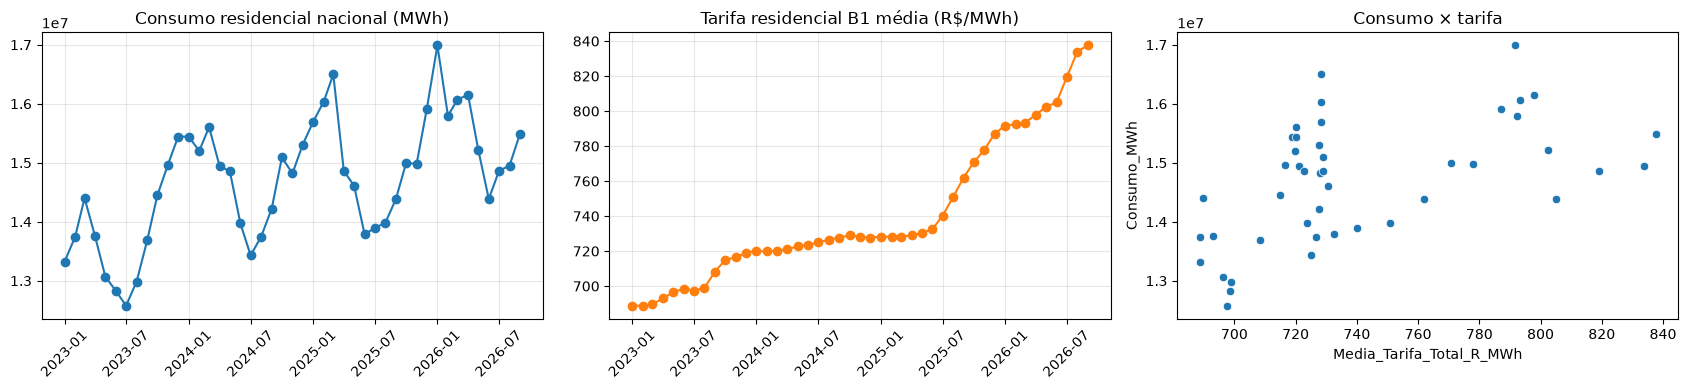

,Consumo_MWh,Media_TUSD_R_MWh,Media_TE_R_MWh,Media_Tarifa_Total_R_MWh
Consumo_MWh,1.000,0.454,0.571,0.530
Media_TUSD_R_MWh,0.454,1.000,0.351,0.981
Media_TE_R_MWh,0.571,0.351,1.000,0.524
Media_Tarifa_Total_R_MWh,0.530,0.981,0.524,1.000


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

axes[0].plot(base["Data"], base["Consumo_MWh"], marker="o")
axes[0].set_title("Consumo residencial nacional (MWh)")
axes[0].tick_params(axis="x", rotation=45); axes[0].grid(alpha=.3)

axes[1].plot(base["Data"], base["Media_Tarifa_Total_R_MWh"], marker="o", color="tab:orange")
axes[1].set_title("Tarifa residencial B1 média (R$/MWh)")
axes[1].tick_params(axis="x", rotation=45); axes[1].grid(alpha=.3)

sns.scatterplot(data=base, x="Media_Tarifa_Total_R_MWh", y="Consumo_MWh", ax=axes[2])
axes[2].set_title("Consumo × tarifa")

plt.tight_layout(); plt.show()

display(base[["Consumo_MWh", "Media_TUSD_R_MWh", "Media_TE_R_MWh",
              "Media_Tarifa_Total_R_MWh"]].corr())

## 8. Regressão linear (mesma especificação da versão original)

Mantivemos o mesmo modelo — **y = consumo**, **X = TUSD e TE médias** — para que a única diferença em relação à versão anterior sejam as correções de bug.

In [10]:
X = base[["Media_TUSD_R_MWh", "Media_TE_R_MWh"]]
y = base["Consumo_MWh"]

modelo = LinearRegression().fit(X, y)
print("Intercepto:", round(modelo.intercept_, 1))
display(pd.DataFrame({"Variavel": X.columns, "Coeficiente": modelo.coef_}))
print("R² na amostra completa:", round(modelo.score(X, y), 3))

Intercepto: -3951419.1


,Variavel,Coeficiente
0,Media_TUSD_R_MWh,"7,978.631"
1,Media_TE_R_MWh,"57,421.135"


R² na amostra completa: 0.4


## 9. Avaliação temporal (treino no passado, teste nos 20% finais)

,Modelo,R²,MAE (MWh),RMSE (MWh),MAPE (%)
0,Regressão TUSD + TE,-0.477,"818,012.735","911,519.530",5.267


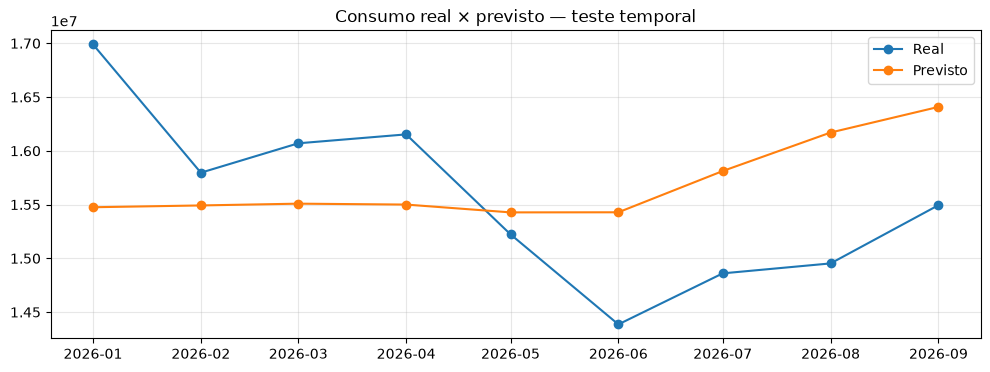

In [11]:
n_teste = max(3, int(np.ceil(len(base) * 0.20)))
X_treino, X_teste = X.iloc[:-n_teste], X.iloc[-n_teste:]
y_treino, y_teste = y.iloc[:-n_teste], y.iloc[-n_teste:]

modelo_teste = LinearRegression().fit(X_treino, y_treino)
previsoes = modelo_teste.predict(X_teste)

def metricas(nome, real, prev):
    return {"Modelo": nome,
            "R²": r2_score(real, prev),
            "MAE (MWh)": mean_absolute_error(real, prev),
            "RMSE (MWh)": mean_squared_error(real, prev) ** 0.5,
            "MAPE (%)": mean_absolute_percentage_error(real, prev) * 100}

resultado = [metricas("Regressão TUSD + TE", y_teste, previsoes)]
display(pd.DataFrame(resultado))

plt.figure(figsize=(12, 4))
plt.plot(base["Data"].iloc[-n_teste:], y_teste.values, marker="o", label="Real")
plt.plot(base["Data"].iloc[-n_teste:], previsoes, marker="o", label="Previsto")
plt.title("Consumo real × previsto — teste temporal"); plt.legend(); plt.grid(alpha=.3)
plt.show()

## 10. Diagnóstico: o modelo é melhor que um chute inteligente?

Um modelo só vale a pena se ganhar de um **baseline** simples. Usamos o **naive sazonal**: "o consumo deste mês vai ser igual ao do mesmo mês do ano passado".

Para ler a tabela:
- **R² negativo** = o modelo erra mais do que simplesmente chutar a média.
- Se o **MAPE da regressão for maior que o do naive**, a tarifa não está ajudando a prever nada.

In [12]:
# Naive sazonal: valor de 12 meses antes (precisa de >= 12 meses antes do teste)
y_completo = base.set_index("Mes")["Consumo_MWh"]
prev_naive = [y_completo.get(m - 12, np.nan) for m in base["Mes"].iloc[-n_teste:]]
if not np.isnan(prev_naive).any():
    resultado.append(metricas("Naive sazonal (mesmo mês ano anterior)", y_teste, prev_naive))

display(pd.DataFrame(resultado).set_index("Modelo"))

,R²,MAE (MWh),RMSE (MWh),MAPE (%)
Modelo,,,,
Regressão TUSD + TE,-0.477,"818,012.735","911,519.530",5.267
Naive sazonal (mesmo mês ano anterior),-0.467,"834,632.967","908,496.904",5.348


## 11. Como ler o resultado

- **Coeficiente positivo para tarifa** não quer dizer que tarifa mais cara faz o consumo subir. Tarifa e consumo sobem juntos com o tempo (inflação + mais clientes), e a regressão captura essa **tendência em comum**. Isso se chama **correlação espúria**.
- A tarifa muda **uma vez por ano** (reajuste); o consumo muda **todo mês** (clima, calendário). Uma variável quase parada não explica uma série que oscila.
- Os bugs foram corrigidos, mas a **conclusão sobre o efeito da tarifa continua não sendo confiável** com esse modelo.

### Próximos passos (fora do escopo desta correção)
1. Usar **consumo por consumidor** (`Consumo_MWh / Consumidores`) como alvo.
2. Incluir **tendência** e **dummies de mês** (sazonalidade).
3. **Deflacionar** a tarifa pelo IPCA.
4. Incluir **temperatura** e atividade econômica.
5. Ampliar o período (a aba tabular vai desde 2004) para ter mais observações.